# BÀI TẬP DỰ ÁN: PHÂN TÍCH & KHAI THÁC DỮ LIỆU — BỘ DỮ LIỆU WINE
**File nộp:** `BUINGOANHQUANG.ipynb`

**Bộ dữ liệu:** Wine recognition (UCI) — 178 mẫu rượu vang Ý, 13 thuộc tính hóa học liên tục, nhãn ∈ {1, 2, 3} tương ứng 3 giống nho/vùng trồng. Bài toán: phân loại loại rượu vang.

**Nội dung:**
- **Phần 1 — Đọc dữ liệu và khám phá:** kích thước, kiểu dữ liệu, phân bố nhãn, min/max/mean; làm sạch (tên cột, missing, duplicate, outlier); EDA trực quan.
- **Phần 2 — Tạo data mới và trực quan hóa:** chọn 13 cột thuộc tính liên tục, chuẩn hóa, giảm chiều PCA, hiển thị không gian 2D với màu theo nhãn.
- **Phần 3 — Huấn luyện mô hình phân loại:** Random Forest, k-fold cross validation k = 10, tinh chỉnh tham số, độ đo F-Score.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

RANDOM_STATE = 42

# Palette 3 lớp đã kiểm chứng colorblind-safe: hue cố định theo lớp
CLASS_COLORS = {1: '#2a78d6', 2: '#eb6834', 3: '#1baf7a'}
BLUE, INK, MUTED, GRID, SURFACE = '#2a78d6', '#0b0b0b', '#52514e', '#e1e0d9', '#fcfcfb'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK,
    'text.color': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.family': 'sans-serif', 'font.size': 11, 'figure.dpi': 110,
})
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)

## Phần 1 — Đọc dữ liệu và khám phá

### 1.1 Đọc dữ liệu

Theo lưu ý của đề bài: **xuất bảng dữ liệu ra file CSV trước khi đọc**. File Excel gồm 2 sheet; dữ liệu nằm ở sheet `wine.data` (sheet `Description` chỉ là mô tả). Cột đầu tiên (`Class`) là nhãn, 13 cột còn lại là thuộc tính — khớp mô tả dataset (178 mẫu, 13 thuộc tính, 3 lớp), không có cột thừa cần loại bỏ.

In [2]:
df_excel = pd.read_excel('D00 - wine.data.xlsx', sheet_name='wine.data')
df_excel.to_csv('wine.csv', index=False)

df = pd.read_csv('wine.csv')
print('Kích thước dữ liệu (dòng, cột):', df.shape)
df.head()

Kích thước dữ liệu (dòng, cột): (178, 14)


,Class,1) Alcohol,2) Malic acid,3) Ash,4) Alcalinity of ash,5) Magnesium,6) Total phenols,7) Flavanoids,8) Nonflavanoid phenols,9) Proanthocyanins,10)Color intensity,11)Hue,12)OD280/OD315 of diluted wines,13)Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


### 1.2 Khám phá tổng quan
Kiểu dữ liệu của các thuộc tính, số lượng thực thể mỗi nhãn, giá trị lớn nhất / bé nhất / trung bình của các cột số.

In [3]:
print('Kiểu dữ liệu của các thuộc tính:')
df.info()

Kiểu dữ liệu của các thuộc tính:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Class                            178 non-null    int64  
 1   1) Alcohol                       178 non-null    float64
 2   2) Malic acid                    178 non-null    float64
 3   3) Ash                           178 non-null    float64
 4   4) Alcalinity of ash             178 non-null    float64
 5   5) Magnesium                     178 non-null    int64  
 6   6) Total phenols                 178 non-null    float64
 7   7) Flavanoids                    178 non-null    float64
 8   8) Nonflavanoid phenols          178 non-null    float64
 9   9) Proanthocyanins               178 non-null    float64
 10  10)Color intensity               178 non-null    float64
 11  11)Hue                           178 non-null    float64
 12  

Số lượng thực thể của mỗi giá trị nhãn:
Class
1    59
2    71
3    48


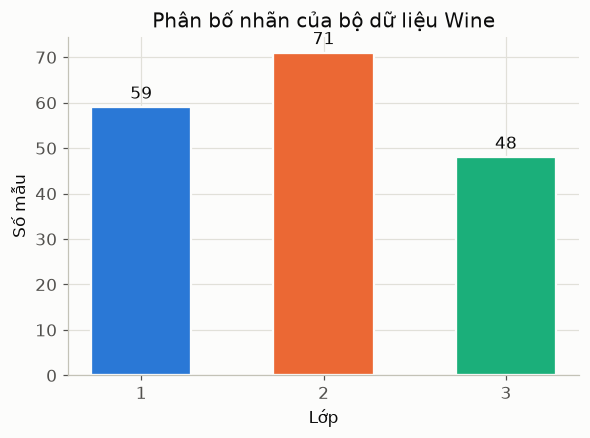

In [4]:
label_counts = df['Class'].value_counts().sort_index()
print('Số lượng thực thể của mỗi giá trị nhãn:')
print(label_counts.to_string())

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([str(k) for k in label_counts.index], label_counts.values,
              color=[CLASS_COLORS[k] for k in label_counts.index],
              width=0.55, edgecolor=SURFACE, linewidth=1.5)
ax.bar_label(bars, padding=3)
ax.set_xlabel('Lớp')
ax.set_ylabel('Số mẫu')
ax.set_title('Phân bố nhãn của bộ dữ liệu Wine')
plt.show()

In [5]:
stats = df.describe().T
print('Giá trị lớn nhất, bé nhất, trung bình của các cột thuộc tính số:')
stats[['min', 'max', 'mean', 'std']].round(3)

Giá trị lớn nhất, bé nhất, trung bình của các cột thuộc tính số:


,min,max,mean,std
Class,1.00,3.00,1.938,0.775
1) Alcohol,11.03,14.83,13.001,0.812
2) Malic acid,0.74,5.80,2.336,1.117
3) Ash,1.36,3.23,2.367,0.274
4) Alcalinity of ash,10.60,30.00,19.495,3.340
5) Magnesium,70.00,162.00,99.742,14.282
6) Total phenols,0.98,3.88,2.295,0.626
7) Flavanoids,0.34,5.08,2.029,0.999
8) Nonflavanoid phenols,0.13,0.66,0.362,0.124
9) Proanthocyanins,0.41,3.58,1.591,0.572


### 1.3 Làm sạch dữ liệu (Data Cleaning)

Các bước thực hiện:
1. **Chuẩn hóa tên cột** — tên gốc kèm số thứ tự (`1) Alcohol`, ...) và khoảng trắng thừa, gây khó khăn khi truy cập.
2. **Kiểm tra giá trị thiếu** (missing values).
3. **Kiểm tra dòng trùng lặp** (duplicates).
4. **Khảo sát ngoại lai** (outlier) bằng quy tắc 1.5×IQR.

In [6]:
def clean_column_name(name):
    name = re.sub(r'^\d+\)\s*', '', name.strip())  # bỏ tiền tố đánh số
    return name.lower().replace('/', '_').replace(' ', '_')

df_clean = df.rename(columns=clean_column_name)
FEATURES = [c for c in df_clean.columns if c != 'class']
print('Tên cột sau khi làm sạch:')
print(list(df_clean.columns))

Tên cột sau khi làm sạch:
['class', 'alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280_od315_of_diluted_wines', 'proline']


In [7]:
print('Số giá trị thiếu theo cột:')
print(df_clean.isna().sum().to_string())
print('\nSố dòng trùng lặp:', df_clean.duplicated().sum())

Số giá trị thiếu theo cột:
class                           0
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280_od315_of_diluted_wines    0
proline                         0

Số dòng trùng lặp: 0


**Kết quả:** không có giá trị thiếu, không có dòng trùng lặp → không cần điền khuyết hay xóa dòng. Tiếp theo: khảo sát outlier.

In [8]:
Q1 = df_clean[FEATURES].quantile(0.25)
Q3 = df_clean[FEATURES].quantile(0.75)
IQR = Q3 - Q1
outlier_mask = (df_clean[FEATURES] < Q1 - 1.5 * IQR) | (df_clean[FEATURES] > Q3 + 1.5 * IQR)
print('Số outlier theo quy tắc 1.5×IQR ở mỗi cột:')
print(outlier_mask.sum().sort_values(ascending=False).to_string())

Số outlier theo quy tắc 1.5×IQR ở mỗi cột:
magnesium                       4
alcalinity_of_ash               4
color_intensity                 4
malic_acid                      3
ash                             3
proanthocyanins                 2
hue                             1
alcohol                         0
total_phenols                   0
nonflavanoid_phenols            0
flavanoids                      0
od280_od315_of_diluted_wines    0
proline                         0


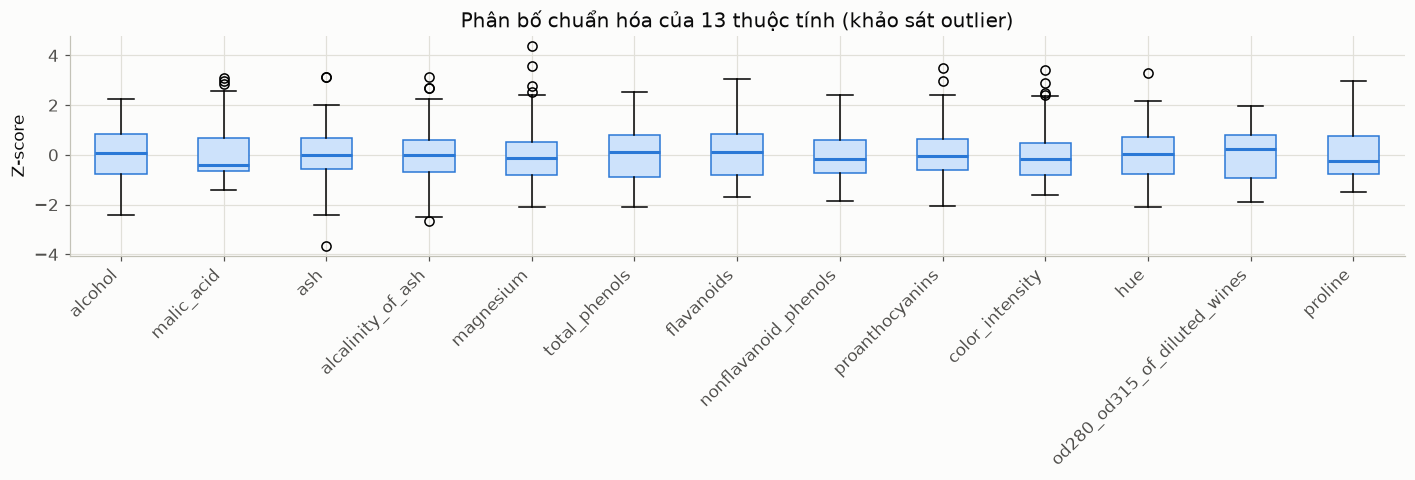

In [9]:
z_scores = (df_clean[FEATURES] - df_clean[FEATURES].mean()) / df_clean[FEATURES].std()

fig, ax = plt.subplots(figsize=(13, 4.5))
bp = ax.boxplot([z_scores[c] for c in FEATURES], tick_labels=FEATURES,
                patch_artist=True, widths=0.5)
for patch in bp['boxes']:
    patch.set_facecolor('#cde2fb')
    patch.set_edgecolor(BLUE)
for median in bp['medians']:
    median.set_color(BLUE)
    median.set_linewidth(2)
ax.set_xticklabels(FEATURES, rotation=45, ha='right')
ax.set_ylabel('Z-score')
ax.set_title('Phân bố chuẩn hóa của 13 thuộc tính (khảo sát outlier)')
fig.tight_layout()
plt.show()

**Nhận xét outlier:** 7/13 cột có giá trị vượt ngưỡng 1.5×IQR (tổng cộng 21 giá trị), nhiều nhất ở `alcalinity_of_ash`, `color_intensity`, `magnesium` (4 giá trị/cột). Đây là **biến thiên tự nhiên** của dữ liệu đo thực tế, không phải lỗi nhập liệu — bộ Wine kinh điển không có bản ghi lỗi.

**Quyết định: giữ nguyên outlier.** Xóa sẽ làm mất thông tin thật; các kỹ thuật ở phần sau (Random Forest, chuẩn hóa + PCA, K-Means/DBSCAN) đều chịu được ngoại lai ở mức này.

In [10]:
df_clean.to_csv('wine_clean.csv', index=False)
print('Đã xuất wine_clean.csv:', df_clean.shape)

Đã xuất wine_clean.csv: (178, 14)


### 1.4 EDA trực quan

**Histogram của 13 thuộc tính:**

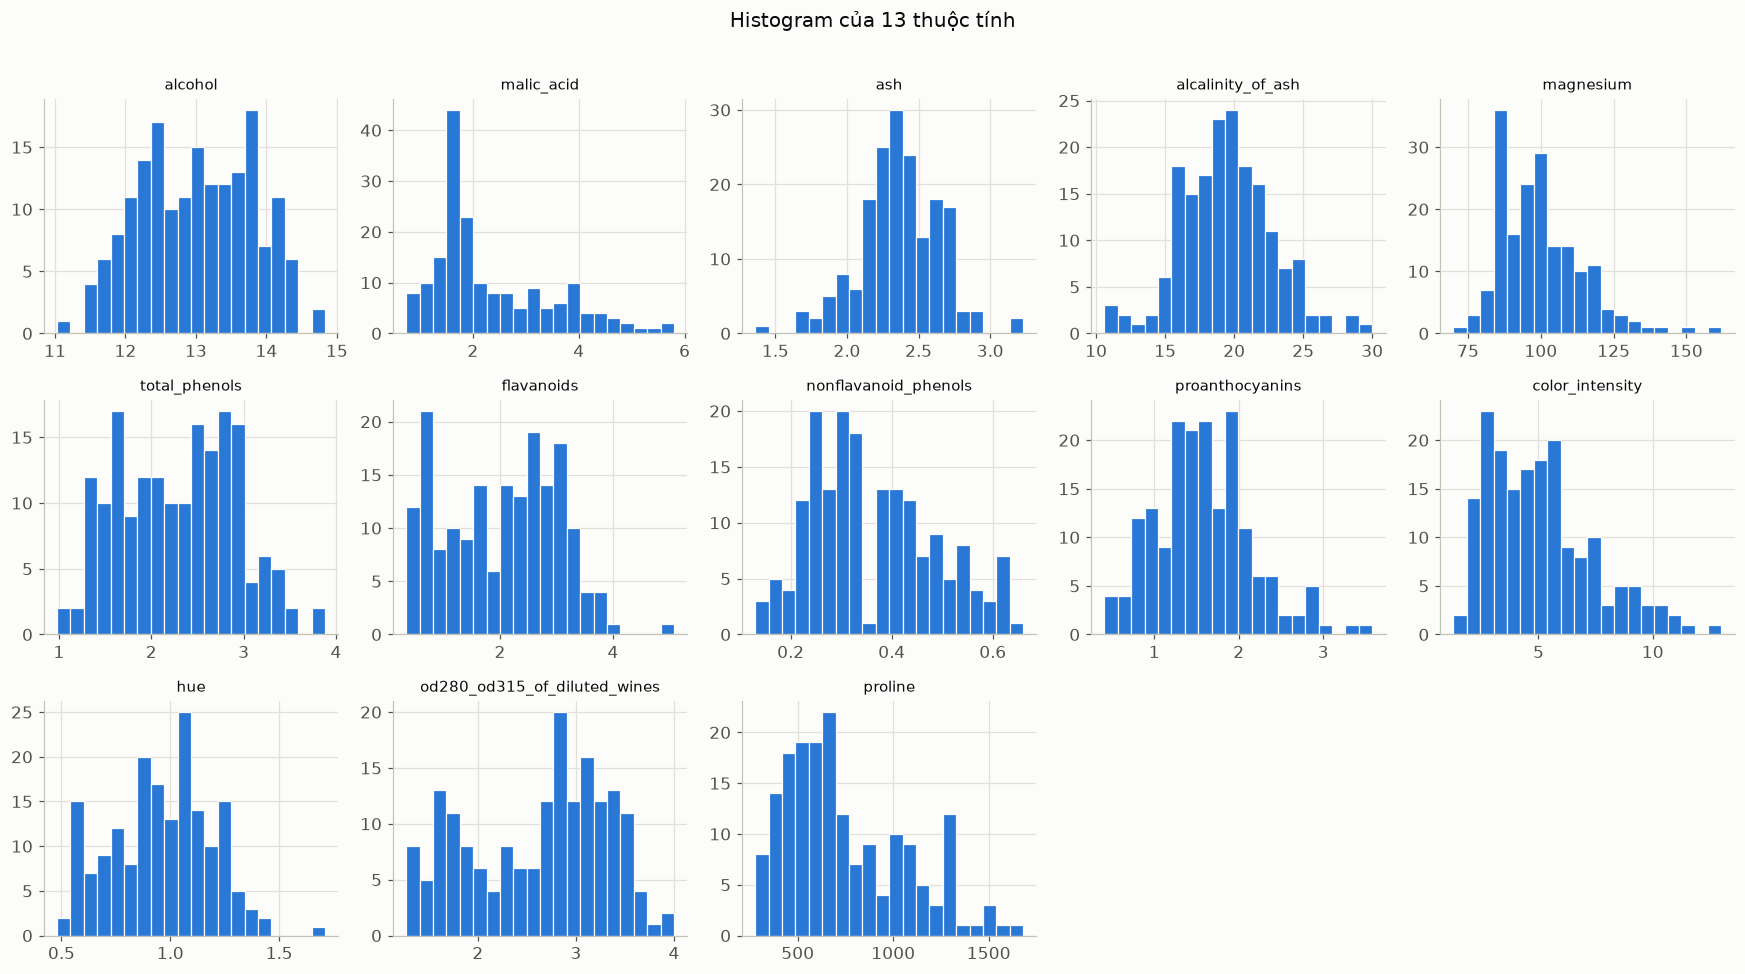

In [11]:
fig, axes = plt.subplots(3, 5, figsize=(16, 9))
for ax, col in zip(axes.flat, FEATURES):
    ax.hist(df_clean[col], bins=20, color=BLUE, edgecolor=SURFACE, linewidth=0.8)
    ax.set_title(col, fontsize=10)
for ax in axes.flat[len(FEATURES):]:
    ax.set_visible(False)
fig.suptitle('Histogram của 13 thuộc tính', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

**Boxplot theo từng lớp** — thuộc tính nào phân biệt 3 lớp rượu vang tốt nhất:

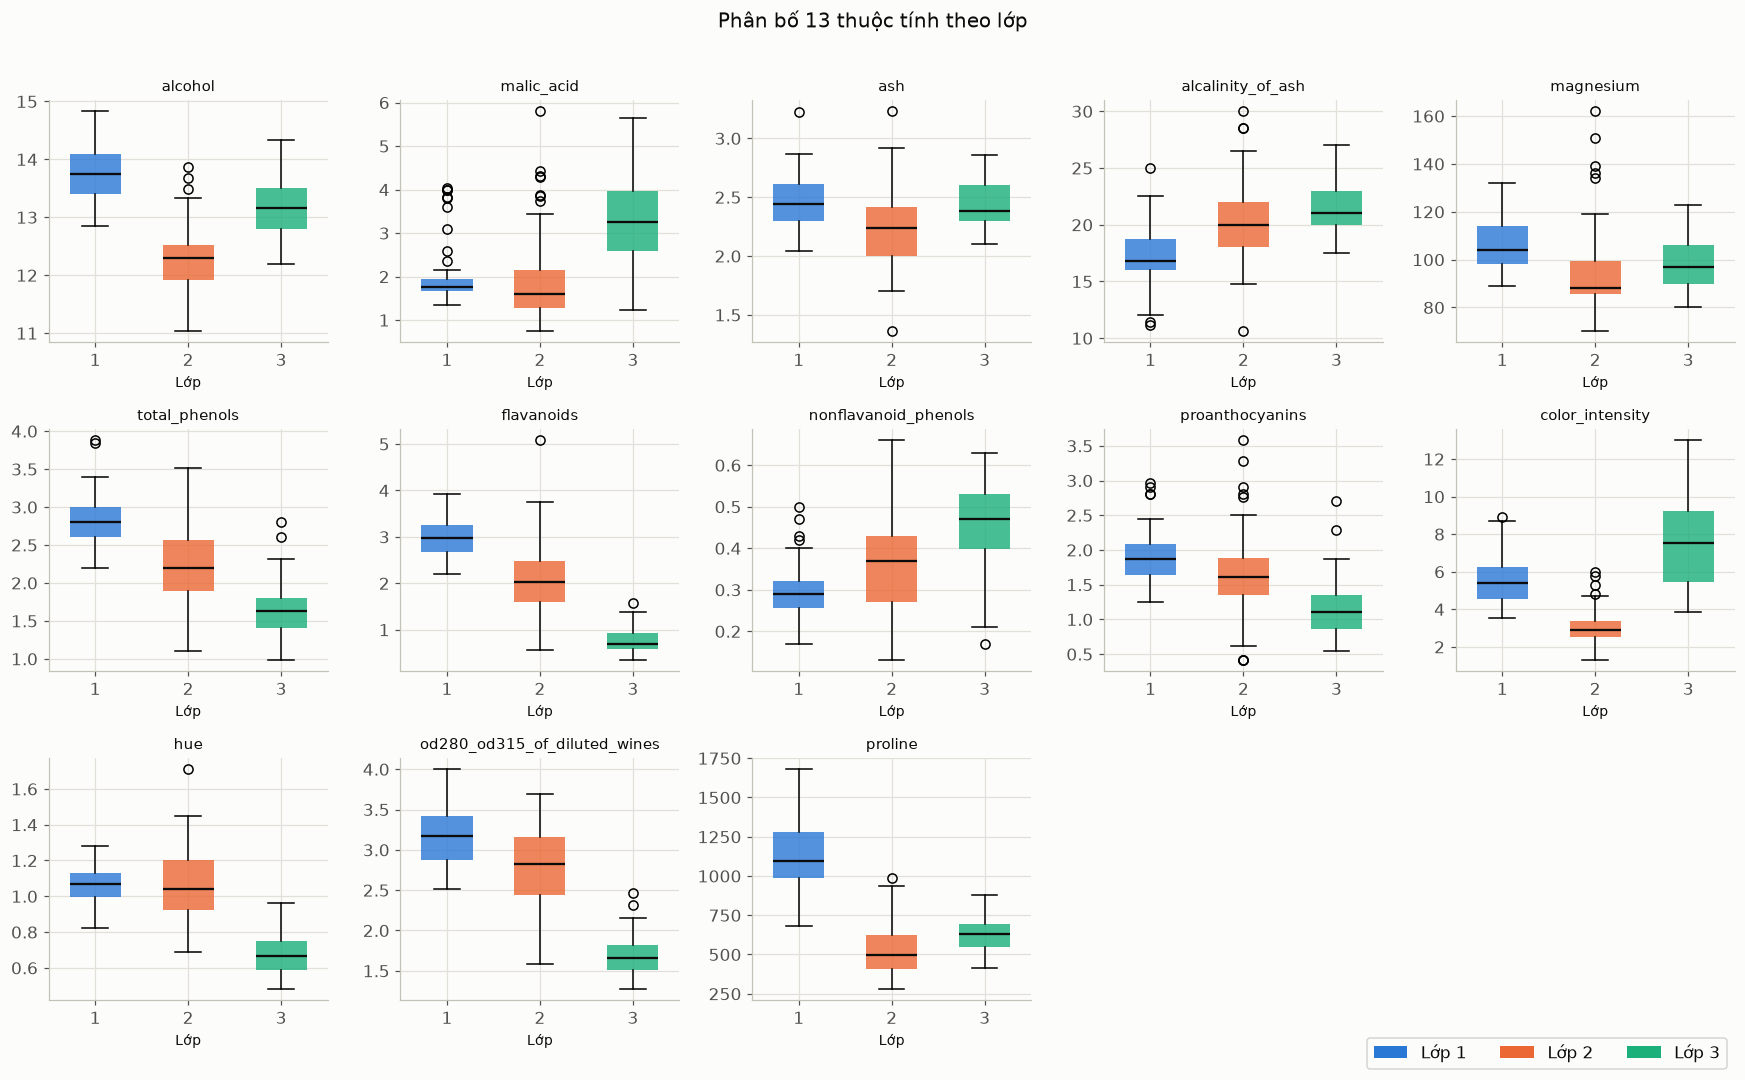

In [12]:
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for ax, col in zip(axes.flat, FEATURES):
    data = [df_clean.loc[df_clean['class'] == k, col] for k in (1, 2, 3)]
    bp = ax.boxplot(data, tick_labels=['1', '2', '3'], patch_artist=True, widths=0.55)
    for patch, k in zip(bp['boxes'], (1, 2, 3)):
        patch.set_facecolor(CLASS_COLORS[k])
        patch.set_alpha(0.8)
        patch.set_edgecolor('none')
    for median in bp['medians']:
        median.set_color(INK)
        median.set_linewidth(1.5)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('Lớp', fontsize=9)
for ax in axes.flat[len(FEATURES):]:
    ax.set_visible(False)
handles = [Patch(facecolor=CLASS_COLORS[k], label=f'Lớp {k}') for k in (1, 2, 3)]
fig.legend(handles=handles, loc='lower right', bbox_to_anchor=(0.99, 0.01), ncol=3)
fig.suptitle('Phân bố 13 thuộc tính theo lớp', fontsize=13)
fig.tight_layout(rect=[0, 0.02, 1, 0.97])
plt.show()

**Ma trận tương quan giữa các thuộc tính:**

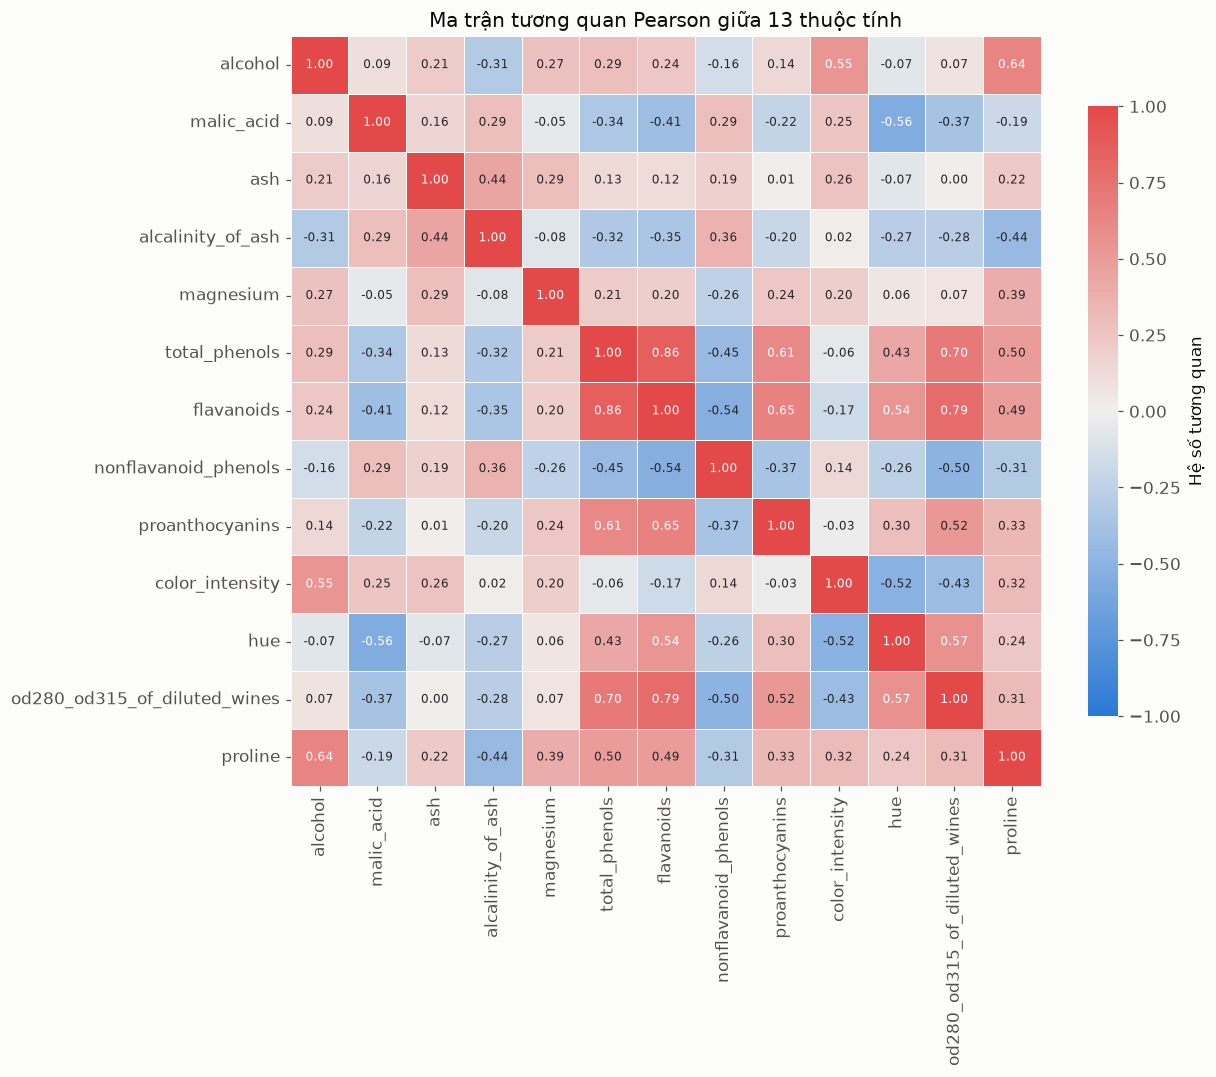

In [13]:
corr = df_clean[FEATURES].corr()
diverging_cmap = LinearSegmentedColormap.from_list('wine_div', ['#2a78d6', '#f0efec', '#e34948'])

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap=diverging_cmap, center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 8}, square=True,
            linewidths=0.5, linecolor=SURFACE,
            cbar_kws={'shrink': 0.8, 'label': 'Hệ số tương quan'}, ax=ax)
ax.set_title('Ma trận tương quan Pearson giữa 13 thuộc tính')
plt.show()

**Nhận xét EDA:**
- Phân bố nhãn hơi lệch: lớp 2 nhiều nhất (71 mẫu), lớp 3 ít nhất (48 mẫu) → khi đánh giá mô hình cần dùng **StratifiedKFold** để mỗi fold giữ nguyên tỉ lệ lớp.
- Nhóm phenol tương quan thuận chặt: `total_phenols` ↔ `flavanoids` (0.865), `flavanoids` ↔ `od280_od315_of_diluted_wines` (0.787); tương quan nghịch đáng kể: `malic_acid` ↔ `hue` (−0.561), `flavanoids` ↔ `nonflavanoid_phenols` (−0.538).
- Nhìn boxplot theo lớp: `flavanoids`, `od280_od315_of_diluted_wines`, `color_intensity`, `proline`, `hue` tách 3 lớp rõ nhất → kỳ vọng bài toán phân loại đạt kết quả cao.
- Thang đo chênh lệch rất lớn (`proline` hàng trăm–nghìn, `hue` quanh 1) → **bắt buộc chuẩn hóa** trước khi dùng PCA hoặc mô hình dựa trên khoảng cách.

## Phần 2 — Tạo data mới và trực quan hóa

Yêu cầu đề bài: chỉ lấy các cột thuộc tính là **giá trị liên tục**, thu giảm số chiều (PCA) và hiển thị trên không gian 2D, các nhãn khác nhau tô màu khác nhau.

Toàn bộ 13 thuộc tính của Wine đều là giá trị liên tục → giữ đủ 13 cột, tách cột nhãn ra riêng.

### 2.1 Chuẩn hóa với StandardScaler

Đưa 13 thuộc tính về mean ≈ 0, std ≈ 1 để mọi thuộc tính đóng góp ngang nhau vào hàm khoảng cách và PCA (nếu không, `proline` sẽ lấn át toàn bộ).

In [14]:
X = df_clean[FEATURES]
y = df_clean['class']

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=FEATURES)

df_scaled = X_scaled.copy()
df_scaled['class'] = y.values
df_scaled.to_csv('wine_scaled.csv', index=False)

print('Sau chuẩn hóa — mean ≈ 0, std ≈ 1:')
print(pd.DataFrame({'mean': X_scaled.mean(), 'std': X_scaled.std(ddof=0)}).round(4).to_string())

Sau chuẩn hóa — mean ≈ 0, std ≈ 1:
                              mean  std
alcohol                       -0.0  1.0
malic_acid                    -0.0  1.0
ash                           -0.0  1.0
alcalinity_of_ash             -0.0  1.0
magnesium                     -0.0  1.0
total_phenols                  0.0  1.0
flavanoids                    -0.0  1.0
nonflavanoid_phenols           0.0  1.0
proanthocyanins               -0.0  1.0
color_intensity                0.0  1.0
hue                            0.0  1.0
od280_od315_of_diluted_wines   0.0  1.0
proline                       -0.0  1.0


### 2.2 Giảm chiều với PCA — chọn số thành phần chính

Khảo sát phương sai tích lũy để chọn số thành phần chính (PC) giữ **≥ 95% phương sai** toàn dữ liệu — đây là "data mới" bản rút gọn dùng cho mô hình/gom cụm nếu cần.

Phương sai tích lũy theo số PC:
[0.362  0.5541 0.6653 0.736  0.8016 0.851  0.8934 0.9202 0.9424 0.9617
 0.9791 0.992  1.    ]

Số PC cần để giữ ≥95% phương sai: 10


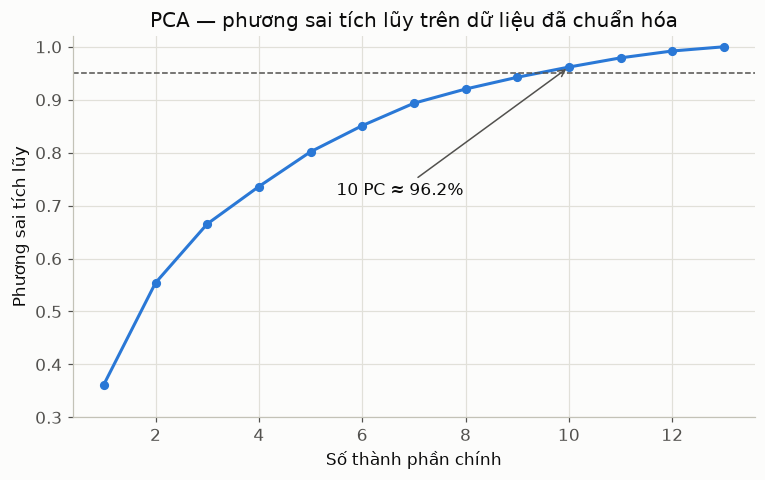

In [15]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components_95 = int(np.searchsorted(cum_var, 0.95) + 1)
print('Phương sai tích lũy theo số PC:')
print(np.round(cum_var, 4))
print(f'\nSố PC cần để giữ ≥95% phương sai: {n_components_95}')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(cum_var) + 1), cum_var, marker='o', markersize=5,
        linewidth=2, color=BLUE)
ax.axhline(0.95, color=MUTED, linestyle='--', linewidth=1)
ax.annotate(f'{n_components_95} PC ≈ {cum_var[n_components_95 - 1]:.1%}',
            xy=(n_components_95, cum_var[n_components_95 - 1]),
            xytext=(n_components_95 - 4.5, 0.72),
            arrowprops=dict(arrowstyle='->', color=MUTED))
ax.set_xlabel('Số thành phần chính')
ax.set_ylabel('Phương sai tích lũy')
ax.set_title('PCA — phương sai tích lũy trên dữ liệu đã chuẩn hóa')
ax.set_ylim(0.3, 1.02)
plt.show()

### 2.3 Trực quan hóa trên không gian 2D

Chiếu dữ liệu xuống 2 thành phần chính đầu tiên (PC1, PC2), mỗi nhãn một màu.

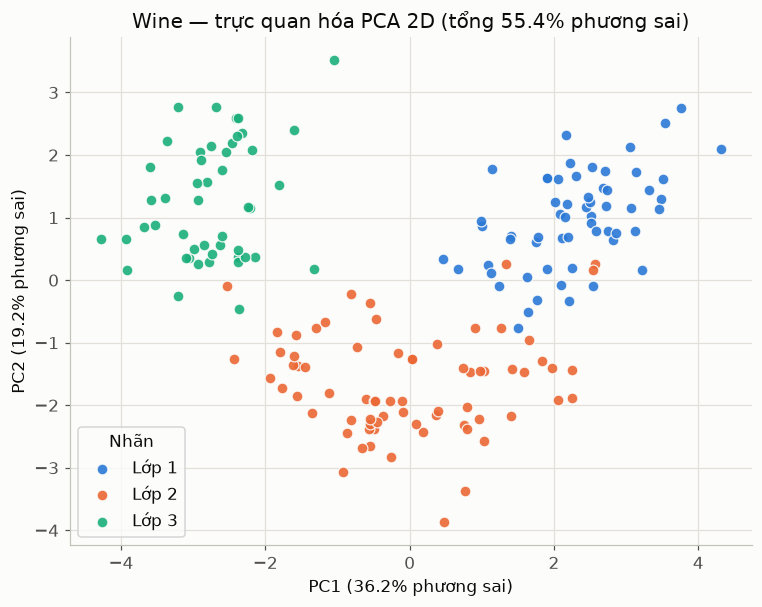

In [16]:
pca_2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca2 = pca_2.fit_transform(X_scaled)
df_pca_2d = pd.DataFrame(X_pca2, columns=['PC1', 'PC2'])
df_pca_2d['class'] = y.values
df_pca_2d.to_csv('wine_pca_2d.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 6))
for k in (1, 2, 3):
    mask = df_pca_2d['class'] == k
    ax.scatter(df_pca_2d.loc[mask, 'PC1'], df_pca_2d.loc[mask, 'PC2'],
               s=50, color=CLASS_COLORS[k], edgecolors=SURFACE, linewidths=0.8,
               alpha=0.9, label=f'Lớp {k}')
v1, v2 = pca_2.explained_variance_ratio_
ax.set_xlabel(f'PC1 ({v1:.1%} phương sai)')
ax.set_ylabel(f'PC2 ({v2:.1%} phương sai)')
ax.set_title(f'Wine — trực quan hóa PCA 2D (tổng {v1 + v2:.1%} phương sai)')
ax.legend(title='Nhãn')
plt.show()

In [17]:
pca_95 = PCA(n_components=n_components_95, random_state=RANDOM_STATE)
X_pca95 = pca_95.fit_transform(X_scaled)
df_pca = pd.DataFrame(X_pca95, columns=[f'PC{i + 1}' for i in range(n_components_95)])
df_pca['class'] = y.values
df_pca.to_csv('wine_pca.csv', index=False)
print(f'Đã xuất wine_pca.csv: {df_pca.shape[0]} dòng × {n_components_95} PC, '
      f'giữ {pca_95.explained_variance_ratio_.sum():.2%} phương sai')

Đã xuất wine_pca.csv: 178 dòng × 10 PC, giữ 96.17% phương sai


**Nhận xét phần 2:** chỉ 2 PC đầu đã giữ ≈55.4% phương sai và 3 lớp tách khá rõ trên mặt phẳng 2D (lớp 3 tách rõ nhất; lớp 1 và 2 hơi chồng lấn ở ranh giới); cần **10 PC** để giữ ≥95% phương sai (96.17%). Điều này nhất quán với EDA: dữ liệu có cấu trúc lớp rõ nhưng thông tin phân bố ở nhiều chiều.

Các file data mới đã xuất: `wine_scaled.csv` (13 thuộc tính chuẩn hóa), `wine_pca_2d.csv` (2 PC để vẽ), `wine_pca.csv` (10 PC, ≥95% phương sai).

## Phần 3 — Huấn luyện mô hình phân loại: Random Forest

Yêu cầu đề bài: **k-fold cross validation với k = 10**, **tinh chỉnh tham số** để mô hình cho kết quả tốt nhất trước khi so sánh, độ đo **F-Score**. Mô hình được chọn: **Random Forest** — bảng kết quả lưu vào `ket_qua_random_forest.csv` để ghép với 2 mô hình còn lại của nhóm (KNN / Naive Bayes / AdaBoost / SVM).

### 3.1 Thiết lập đánh giá

- **StratifiedKFold k = 10** (shuffle, seed 42): mỗi fold giữ nguyên tỉ lệ 3 lớp (59/71/48) — tránh fold bị lệch lớp.
- **F1-macro**: trung bình F1 của 3 lớp với trọng số bằng nhau, không để lớp đông lấn át lớp ít; kèm Accuracy để tham khảo.
- Random Forest là mô hình cây, **không nhạy thang đo** nên dùng trực tiếp `wine_clean.csv`, không cần bản chuẩn hóa.

In [18]:
df_model = pd.read_csv('wine_clean.csv')
X = df_model[FEATURES]
y = df_model['class']

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
scoring = {'f1_macro': 'f1_macro', 'accuracy': 'accuracy'}

rf_default = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
cv_default = cross_validate(rf_default, X, y, cv=cv, scoring=scoring, n_jobs=-1)
print('RF mặc định — F1-macro: {:.4f} ± {:.4f} | Accuracy: {:.4f} ± {:.4f}'.format(
    cv_default['test_f1_macro'].mean(), cv_default['test_f1_macro'].std(),
    cv_default['test_accuracy'].mean(), cv_default['test_accuracy'].std()))

RF mặc định — F1-macro: 0.9893 ± 0.0215 | Accuracy: 0.9889 ± 0.0222


### 3.2 Tinh chỉnh tham số — GridSearchCV với 10-fold CV

Lưới tham số: số cây (`n_estimators`), độ sâu tối đa (`max_depth`), điều kiện tách nút (`min_samples_split`, `min_samples_leaf`), số thuộc tính xét mỗi lần tách (`max_features`). Tổng cộng 72 tổ hợp × 10 fold = 720 lần huấn luyện, chấm điểm bằng F1-macro; chọn tổ hợp tốt nhất rồi refit trên toàn bộ dữ liệu.

In [19]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2'],
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    param_grid, cv=cv, scoring=scoring, refit='f1_macro', n_jobs=-1,
)
grid.fit(X, y)
print('Tham số tốt nhất:', grid.best_params_)
print('F1-macro tốt nhất (CV10): {:.4f}'.format(grid.best_score_))

Tham số tốt nhất: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
F1-macro tốt nhất (CV10): 0.9893


### 3.3 Bảng so sánh hiệu năng (độ đo F-Score, k = 10)

In [20]:
best_i = grid.best_index_
results = pd.DataFrame([
    {
        'Mô hình': 'Random Forest (mặc định)',
        'Tham số tốt nhất': 'mặc định',
        'F1-macro (k=10)': '{:.4f} ± {:.4f}'.format(
            cv_default['test_f1_macro'].mean(), cv_default['test_f1_macro'].std()),
        'Accuracy (k=10)': '{:.4f} ± {:.4f}'.format(
            cv_default['test_accuracy'].mean(), cv_default['test_accuracy'].std()),
    },
    {
        'Mô hình': 'Random Forest (tinh chỉnh)',
        'Tham số tốt nhất': str(grid.best_params_),
        'F1-macro (k=10)': '{:.4f} ± {:.4f}'.format(
            grid.best_score_, grid.cv_results_['std_test_f1_macro'][best_i]),
        'Accuracy (k=10)': '{:.4f} ± {:.4f}'.format(
            grid.cv_results_['mean_test_accuracy'][best_i],
            grid.cv_results_['std_test_accuracy'][best_i]),
    },
])
results.to_csv('ket_qua_random_forest.csv', index=False, encoding='utf-8-sig')
results

,Mô hình,Tham số tốt nhất,F1-macro (k=10),Accuracy (k=10)
0,Random Forest (mặc định),mặc định,0.9893 ± 0.0215,0.9889 ± 0.0222
1,Random Forest (tinh chỉnh),"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.9893 ± 0.0215,0.9889 ± 0.0222


### 3.4 Đánh giá chi tiết mô hình tốt nhất

Dự đoán **out-of-fold** trên toàn bộ 178 mẫu: mỗi mẫu được dự đoán bởi mô hình không nhìn thấy nó khi huấn luyện → classification report và confusion matrix không bị thiên lệch do huấn luyện.

In [21]:
y_pred = cross_val_predict(grid.best_estimator_, X, y, cv=cv, n_jobs=-1)
print(classification_report(y, y_pred, digits=4))

              precision    recall  f1-score   support

           1     0.9833    1.0000    0.9916        59
           2     1.0000    0.9718    0.9857        71
           3     0.9796    1.0000    0.9897        48

    accuracy                         0.9888       178
   macro avg     0.9876    0.9906    0.9890       178
weighted avg     0.9890    0.9888    0.9887       178



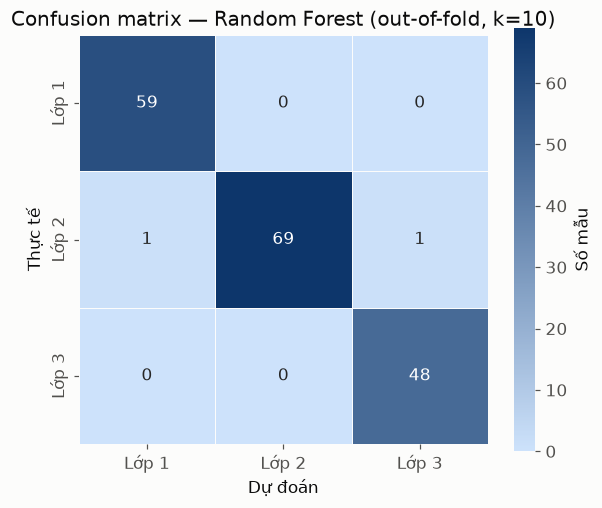

In [22]:
cm = confusion_matrix(y, y_pred)
sequential_cmap = LinearSegmentedColormap.from_list('wine_seq', ['#cde2fb', '#0d366b'])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap=sequential_cmap, square=True,
            linewidths=0.5, linecolor=SURFACE, cbar_kws={'label': 'Số mẫu'},
            xticklabels=['Lớp 1', 'Lớp 2', 'Lớp 3'],
            yticklabels=['Lớp 1', 'Lớp 2', 'Lớp 3'], ax=ax)
ax.set_xlabel('Dự đoán')
ax.set_ylabel('Thực tế')
ax.set_title('Confusion matrix — Random Forest (out-of-fold, k=10)')
plt.show()

### 3.5 Mức độ quan trọng của thuộc tính

Mô hình tốt nhất đã được refit trên toàn bộ dữ liệu; `feature_importances_` (Gini importance) cho biết thuộc tính nào đóng góp nhiều nhất vào việc phân lớp — dùng để đối chiếu với nhận xét EDA.

Bảng Gini importance:
nonflavanoid_phenols            0.0073
ash                             0.0155
proanthocyanins                 0.0184
magnesium                       0.0259
alcalinity_of_ash               0.0299
malic_acid                      0.0331
total_phenols                   0.0351
hue                             0.0769
od280_od315_of_diluted_wines    0.1118
proline                         0.1370
alcohol                         0.1416
color_intensity                 0.1730
flavanoids                      0.1945


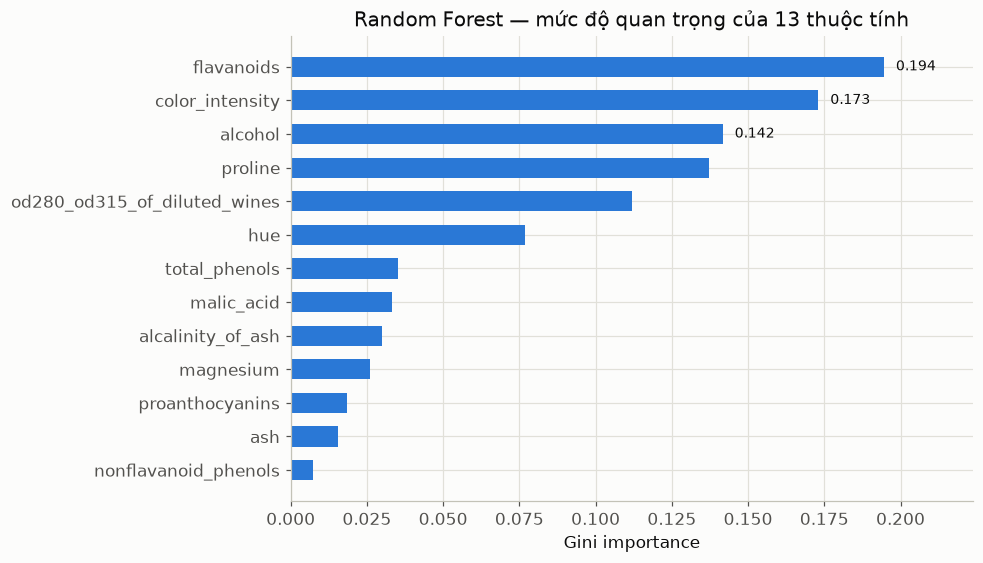

In [23]:
importances = pd.Series(grid.best_estimator_.feature_importances_, index=FEATURES).sort_values()
print('Bảng Gini importance:')
print(importances.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(importances.index, importances.values, color=BLUE, height=0.6)
for bar, val in zip(bars[-3:], importances.values[-3:]):
    ax.text(val + 0.004, bar.get_y() + bar.get_height() / 2,
            f'{val:.3f}', va='center', fontsize=9)
ax.set_xlabel('Gini importance')
ax.set_title('Random Forest — mức độ quan trọng của 13 thuộc tính')
ax.set_xlim(0, importances.max() * 1.15)
plt.show()

## Tổng kết

- **Phần 1:** dữ liệu 178 × 14 (1 nhãn + 13 thuộc tính liên tục), không missing, không duplicate; tên cột chuẩn hóa; outlier tự nhiên giữ nguyên có giải trình. EDA cho thấy 3 lớp phân biệt rõ qua `flavanoids`, `color_intensity`, `proline`, `hue`, `od280_od315_of_diluted_wines`.
- **Phần 2:** tạo data mới gồm `wine_scaled.csv` (chuẩn hóa), `wine_pca_2d.csv` (trực quan 2D, ≈55.4% phương sai, màu theo nhãn), `wine_pca.csv` (10 PC, ≥95% phương sai).
- **Phần 3:** Random Forest với 10-fold CV; bảng so sánh mặc định vs tinh chỉnh theo F1-macro lưu tại `ket_qua_random_forest.csv`; confusion matrix out-of-fold và Gini importance củng cố nhận xét EDA.
- **Việc còn lại của nhóm:** bổ sung 2 mô hình nữa vào bảng so sánh (KNN / Naive Bayes / AdaBoost / SVM) và phần gom cụm K-Means, DBSCAN (đánh giá bằng Adjusted Rand Index).